In [1]:
# Cell 1: Setup & Dependencies
# Install if needed: pip install scipy pandas numpy matplotlib

import numpy as np
import pandas as pd
from scipy.signal import decimate, find_peaks
from scipy.ndimage import median_filter
import matplotlib.pyplot as plt
from pathlib import Path
import gc
import json

print("✅ All dependencies loaded successfully")
print(f"NumPy: {np.__version__}")
print(f"Working directory: {Path.cwd()}")

✅ All dependencies loaded successfully
NumPy: 2.5.3
Working directory: /home/lichenaut/CodiumProjects/marginum


In [2]:
# Cell 2: Configuration Parameters (ADC2 ONLY)

CONFIG = {
    # Sampling
    'original_fs': 50000,        # Hz
    'target_fs': 1000,          # Hz (after decimation)
    
    # Peak detection - TUNED FOR ADC2
    'prominence_std_mult': 1.5,  # More sensitive (catches more events)
    'min_distance_sec': 0.1,     # 100 ms between peaks
    'min_width_sec': 0.01,       # 10 ms minimum width
    
    # Baseline
    'baseline_window_sec': 5.0,   # 5 second rolling window
    
    # Data paths
    'data_dir': './Test signals from previous years/Suction data/Original',
    'test_files': [
        '5. suction_HIGH_CONC_1ml_and_no_resuction.csv',
        '6. suction_MIDDLE_CONC_3ml_(and_no_resuction).csv',
        # '1. LONG_suction_HIGH_CONC_4ml_(and_3_times_resuction).csv',
    ]
}

# Derived configs
CONFIG['decimation_factor'] = CONFIG['original_fs'] // CONFIG['target_fs']
CONFIG['min_distance_samples'] = int(CONFIG['min_distance_sec'] * CONFIG['target_fs'])
CONFIG['min_width_samples'] = int(CONFIG['min_width_sec'] * CONFIG['target_fs'])
CONFIG['baseline_window_samples'] = int(CONFIG['baseline_window_sec'] * CONFIG['target_fs'])

print("✅ Configuration:")
print(f"   FS: {CONFIG['original_fs']} → {CONFIG['target_fs']} Hz ({CONFIG['decimation_factor']}×)")
print(f"   Prominence: {CONFIG['prominence_std_mult']}× std")
print(f"   Min distance: {CONFIG['min_distance_sec']*1000:.0f} ms")
print(f"   Min width: {CONFIG['min_width_sec']*1000:.1f} ms")

✅ Configuration:
   FS: 50000 → 1000 Hz (50×)
   Prominence: 1.5× std
   Min distance: 100 ms
   Min width: 10.0 ms


Loading: Test signals from previous years/Suction data/Original/5. suction_HIGH_CONC_1ml_and_no_resuction.csv
✅ Loaded 3,514,112 samples
   ADC2 stats: mean=629.6, std=97.4


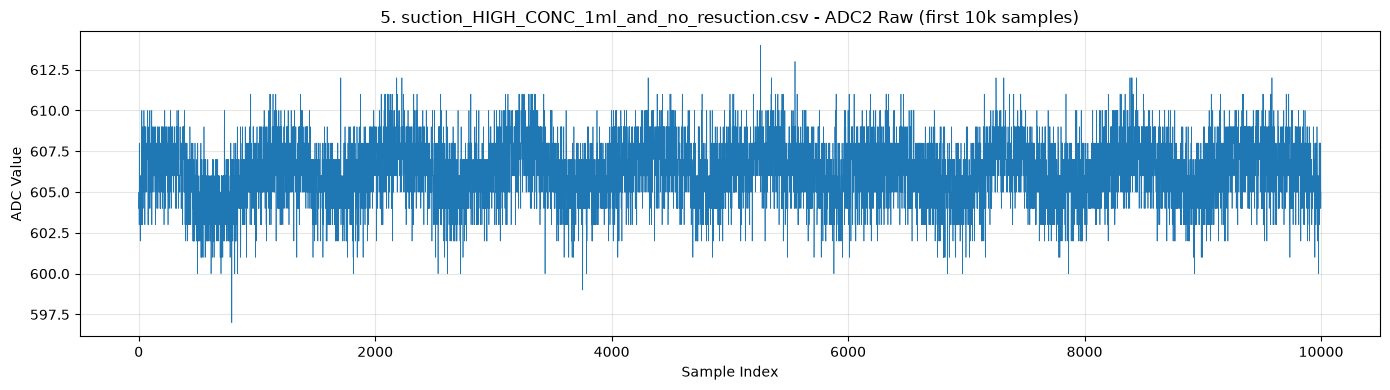

⏱️ Duration: 70.3s (1.2 min)


In [3]:
# Cell 3: Load and Inspect ADC2 Signal
def load_csv_file(filepath):
    """Load CSV, return adc2 column only."""
    df = pd.read_csv(filepath, sep='\t' if '\t' in open(filepath).readline() else ',')
    return df['adc2'].values  # Single channel

# Load first test file
test_file = Path(CONFIG['data_dir']) / CONFIG['test_files'][0]
print(f"Loading: {test_file}")

raw_adc2 = load_csv_file(test_file)
print(f"✅ Loaded {len(raw_adc2):,} samples")
print(f"   ADC2 stats: mean={np.mean(raw_adc2):.1f}, std={np.std(raw_adc2):.1f}")

# Quick visualization (first 10k samples)
plt.figure(figsize=(14, 4))
plt.plot(raw_adc2[:10000], linewidth=0.5)
plt.title(f'{test_file.name} - ADC2 Raw (first 10k samples)')
plt.xlabel('Sample Index')
plt.ylabel('ADC Value')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Duration estimate
duration_sec = len(raw_adc2) / CONFIG['original_fs']
print(f"⏱️ Duration: {duration_sec:.1f}s ({duration_sec/60:.1f} min)")

🔄 Decimating to 1000 Hz...
✅ Done: 70,283 samples (1000 Hz)
   Reduction: 1757075×


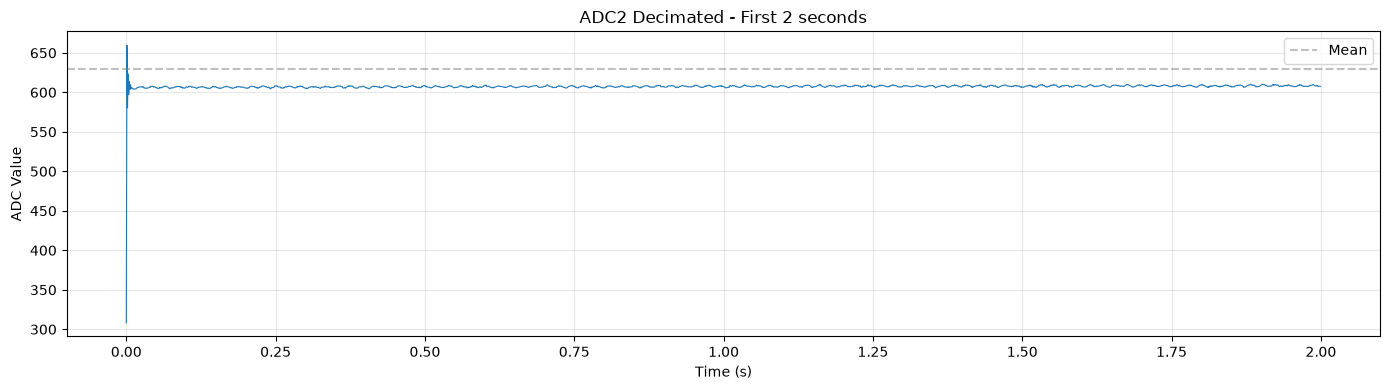

In [4]:
# Cell 4: Downsample (Decimation)
print("🔄 Decimating to 1000 Hz...")

factor = CONFIG['decimation_factor']
adc2_dec = decimate(raw_adc2, factor, ftype='fir', zero_phase=True)
time_dec = np.arange(len(adc2_dec)) / CONFIG['target_fs']

del raw_adc2  # Free memory
gc.collect()

print(f"✅ Done: {len(adc2_dec):,} samples ({CONFIG['target_fs']} Hz)")
print(f"   Reduction: {len(adc2_dec)/len(decimate(np.ones(100), factor))*factor:.0f}×")

# Plot first 2 seconds
samples_show = 2 * CONFIG['target_fs']
plt.figure(figsize=(14, 4))
plt.plot(time_dec[:samples_show], adc2_dec[:samples_show], linewidth=0.8)
plt.axhline(np.mean(adc2_dec), color='gray', linestyle='--', alpha=0.5, label='Mean')
plt.title('ADC2 Decimated - First 2 seconds')
plt.xlabel('Time (s)')
plt.ylabel('ADC Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

🔄 Applying baseline correction...
✅ Baseline removed
   Centered stats: mean=23.77, std=97.49


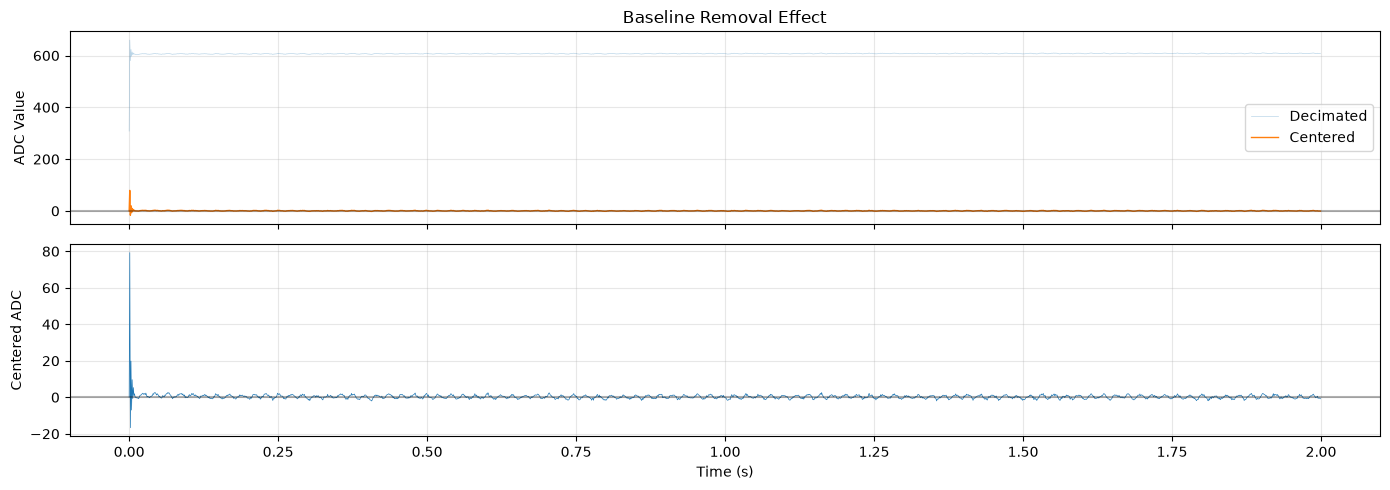

In [5]:
# Cell 5: Baseline Correction (Rolling Median)
def subtract_rolling_median(signal, window_samples):
    """Remove slow baseline drift using rolling median."""
    padded = np.pad(signal, (window_samples//2, window_samples//2), mode='edge')
    baseline = median_filter(padded, size=window_samples)
    centered = padded[window_samples//2:-window_samples//2] - baseline[window_samples//2:-window_samples//2]
    return centered

print("🔄 Applying baseline correction...")

window = CONFIG['baseline_window_samples']
adc2_centered = subtract_rolling_median(adc2_dec, window)

print(f"✅ Baseline removed")
print(f"   Centered stats: mean={np.mean(adc2_centered):.2f}, std={np.std(adc2_centered):.2f}")

# Visualize baseline removal
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5), sharex=True)

ax1.plot(time_dec[:samples_show], adc2_dec[:samples_show], alpha=0.3, linewidth=0.5, label='Decimated')
ax1.plot(time_dec[:samples_show], adc2_centered[:samples_show], linewidth=1, label='Centered')
ax1.axhline(0, color='black', linestyle='-', alpha=0.3)
ax1.set_ylabel('ADC Value')
ax1.legend()
ax1.set_title('Baseline Removal Effect')
ax1.grid(True, alpha=0.3)

ax2.plot(time_dec[:samples_show], adc2_centered[:samples_show], linewidth=0.5)
ax2.axhline(0, color='black', linestyle='-', alpha=0.3)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Centered ADC')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# Cell 6: Peak Detection (Single Channel - ADC2)
def detect_peaks_single_channel(sig, prominence_mult, min_dist, min_width, fs):
    """Detect peaks using scipy.signal.find_peaks."""
    baseline_std = np.std(sig)
    prominence_threshold = prominence_mult * baseline_std
    
    peaks, props = find_peaks(
        sig,
        prominence=prominence_threshold,
        distance=min_dist,
        width=min_width
    )
    
    print(f"   Baseline noise: {baseline_std:.2f}")
    print(f"   Prominence threshold: {prominence_threshold:.2f}")
    print(f"   Peaks detected: {len(peaks)}")
    
    return peaks, props, prominence_threshold

print("🔍 Running peak detection...")

peaks, props, prom_thresh = detect_peaks_single_channel(
    adc2_centered,
    CONFIG['prominence_std_mult'],
    CONFIG['min_distance_samples'],
    CONFIG['min_width_samples'],
    CONFIG['target_fs']
)

print(f"✅ Complete! Duration: {time_dec[-1]:.2f}s, Rate: {len(peaks)/time_dec[-1]:.2f}/s")

🔍 Running peak detection...
   Baseline noise: 97.49
   Prominence threshold: 146.24
   Peaks detected: 65
✅ Complete! Duration: 70.28s, Rate: 0.92/s


📊 Visualizing 65 peaks...


/tmp/ipykernel_34484/3424010207.py:30: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


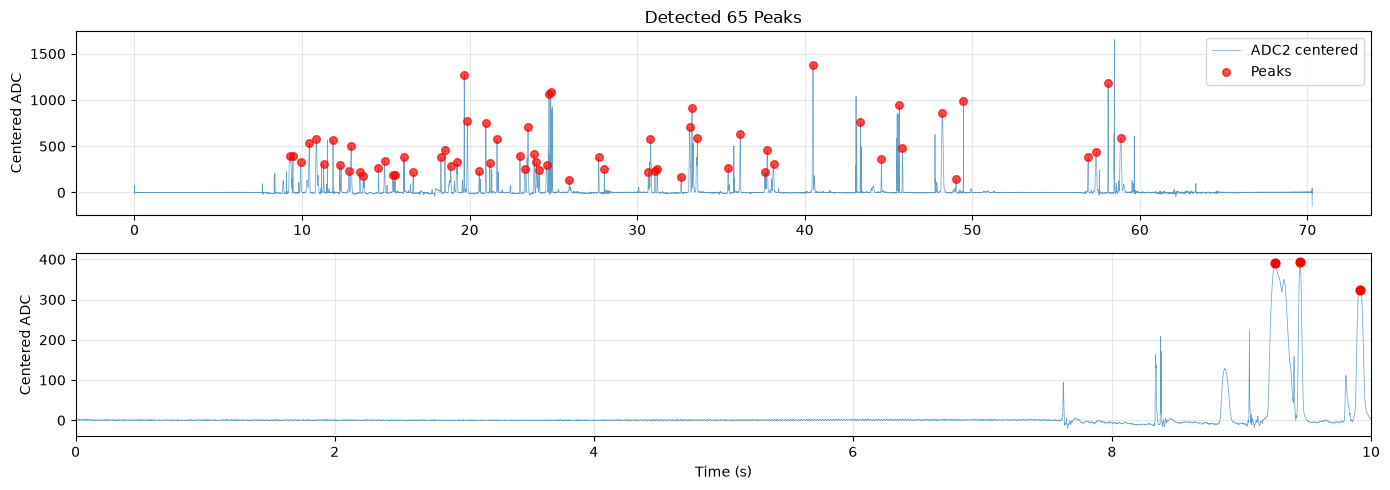

📸 Saving high-res visualization...
✅ Saved: 5. suction_HIGH_CONC_1ml_and_no_resuction_peak_detection.png
   Resolution: 4800 × 2700 px


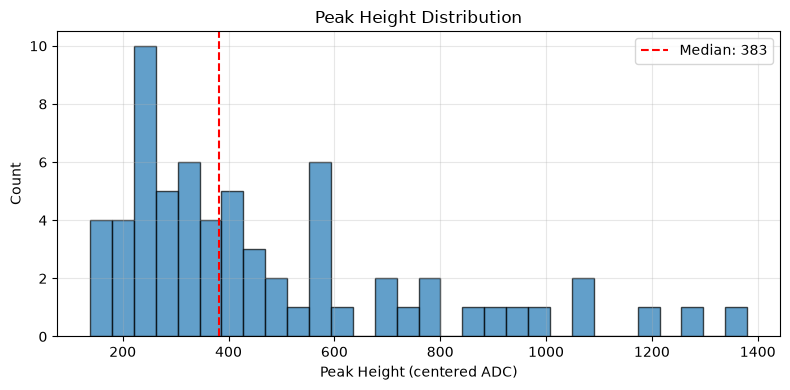

In [7]:
# Cell 7: Visualize & Save Detected Peaks

print(f"📊 Visualizing {len(peaks)} peaks...")

# Convert peak indices to time
peak_times = peaks / CONFIG['target_fs']
peak_heights = adc2_centered[peaks]

# Inline display (for quick look)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5), constrained_layout=True)

ax1.plot(time_dec, adc2_centered, linewidth=0.5, alpha=0.7, label='ADC2 centered')
ax1.scatter(peak_times, peak_heights, color='red', s=30, alpha=0.7, label='Peaks', zorder=5)
ax1.set_ylabel('Centered ADC')
ax1.legend()
ax1.set_title(f'Detected {len(peaks)} Peaks')
ax1.grid(True, alpha=0.3)

# Zoom to first 10 seconds
zoom_end = min(10, time_dec[-1])
zoom_mask = time_dec <= zoom_end
ax2.plot(time_dec[zoom_mask], adc2_centered[zoom_mask], linewidth=0.5, alpha=0.7)
ax2.scatter(peak_times[peak_times <= zoom_end], peak_heights[peak_times <= zoom_end], 
            color='red', s=40, zorder=5)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Centered ADC')
ax2.set_xlim(0, zoom_end)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ===== SAVE HIGH-RESOLUTION IMAGE =====
print(f"📸 Saving high-res visualization...")

# Create figure with 3 panels (full, zoom, histogram)
save_fig, axes = plt.subplots(3, 1, figsize=(16, 9), constrained_layout=True)

# Panel 1: Full timeline
axes[0].plot(time_dec, adc2_centered, 'b-', linewidth=0.8, alpha=0.7)
axes[0].scatter(peak_times, peak_heights, color='red', s=35, 
                facecolors='none', edgecolors='red', linewidths=1.5, zorder=5)
axes[0].axhline(0, color='black', linestyle='-', alpha=0.3)
axes[0].set_title(f'Total: {len(peaks)} Peaks Detected', fontsize=11, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Panel 2: Zoomed (first 30s)
zoom_mask = time_dec <= min(30, time_dec[-1])
axes[1].plot(time_dec[zoom_mask], adc2_centered[zoom_mask], 'b-', linewidth=1.0)
zoom_peaks = peaks[peak_times <= min(30, time_dec[-1])]
axes[1].scatter(peak_times[peak_times <= min(30, time_dec[-1])], 
                peak_heights[peak_times <= min(30, time_dec[-1])],
                color='red', s=45, facecolors='none', edgecolors='red', linewidths=2.0, zorder=5)
axes[1].set_xlim(0, min(30, time_dec[-1]))
axes[1].grid(True, alpha=0.3)

# Panel 3: Histogram
axes[2].hist(peak_heights, bins=40, edgecolor='black', alpha=0.7, color='purple')
axes[2].axvline(np.median(peak_heights), color='red', linestyle='--', linewidth=2, 
                label=f'Median: {np.median(peak_heights):.0f}')
axes[2].set_xlabel('Peak Height (ADC)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Overall title
save_fig.suptitle(f'Fluorescence Detection - {test_file.name}', 
                  fontsize=12, fontweight='bold', y=0.995)

# Save
output_image = test_file.stem + "_peak_detection.png"
save_fig.savefig(output_image, dpi=300, bbox_inches='tight', 
                 facecolor='white', edgecolor='none')
plt.close(save_fig)

print(f"✅ Saved: {output_image}")
print(f"   Resolution: {save_fig.get_size_inches()[0]*300:.0f} × {save_fig.get_size_inches()[1]*300:.0f} px")

# Histogram separately (inline)
fig_hist, ax_hist = plt.subplots(figsize=(8, 4))
ax_hist.hist(peak_heights, bins=30, edgecolor='black', alpha=0.7)
ax_hist.axvline(np.median(peak_heights), color='red', linestyle='--', 
                label=f'Median: {np.median(peak_heights):.0f}')
ax_hist.set_xlabel('Peak Height (centered ADC)')
ax_hist.set_ylabel('Count')
ax_hist.set_title('Peak Height Distribution')
ax_hist.legend()
ax_hist.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Cell 8: Extract Event Metrics & Export
def extract_event_metrics(peaks, signal, time_vec, fs):
    """Calculate features for each detected peak."""
    events = []
    
    for idx in peaks:
        t = int(idx)
        seg_start = max(0, t - 50)
        seg_end = min(len(time_vec), t + 50)
        segment = signal[seg_start:seg_end]
        
        event = {
            'timestamp_sec': time_vec[t],
            'peak_height': signal[t],
            'segment_mean': np.mean(segment),
            'segment_std': np.std(segment),
            'peak_index': int(t)
        }
        events.append(event)
    
    return pd.DataFrame(events)

print("📊 Calculating event metrics...")
events_df = extract_event_metrics(peaks, adc2_centered, time_dec, CONFIG['target_fs'])

print(f"✅ Extracted {len(events_df)} events")
print("\nSummary statistics:")
print(events_df.describe().round(2))

# Save to CSV
output_file = test_file.stem + "_detected_events.csv"
if len(events_df) > 0:
    events_df.to_csv(output_file, index=False)
    print(f"💾 Saved to: {output_file}")
else:
    print("⚠️ No events detected")

📊 Calculating event metrics...
✅ Extracted 65 events

Summary statistics:
       timestamp_sec  peak_height  segment_mean  segment_std  peak_index
count          65.00        65.00         65.00        65.00       65.00
mean           27.19       478.53        199.03       152.97    27185.54
std            13.54       294.84        141.83        91.15    13535.18
min             9.26       138.28         50.72        44.08     9257.00
25%            16.07       256.80         98.22        91.46    16066.00
50%            23.98       382.84        161.96       129.20    23979.00
75%            35.43       585.09        255.13       176.30    35433.00
max            58.86      1379.98        728.31       496.66    58856.00
💾 Saved to: 5. suction_HIGH_CONC_1ml_and_no_resuction_detected_events.csv


🔄 Batch processing...
   [1/2] 5. suction_HIGH_CONC_1ml_and_no_resuction.csv
   Baseline noise: 97.49
   Prominence threshold: 146.24
   Peaks detected: 65
      ✅ 65 events (55.5/min)
   [2/2] 6. suction_MIDDLE_CONC_3ml_(and_no_resuction).csv
   Baseline noise: 56.56
   Prominence threshold: 84.84
   Peaks detected: 83
      ✅ 83 events (38.7/min)

=== BATCH SUMMARY ===


'                                             file  events_detected  events_per_min\n    5. suction_HIGH_CONC_1ml_and_no_resuction.csv               65           55.49\n6. suction_MIDDLE_CONC_3ml_(and_no_resuction).csv               83           38.74'

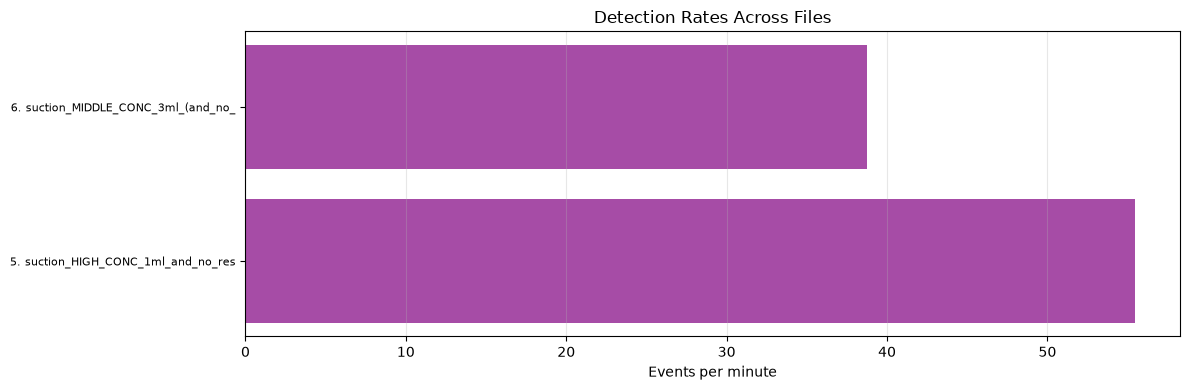

✅ Batch complete. Memory freed.


In [9]:
# Cell 9: Memory-Efficient Batch Processing
def process_file_memory_efficient(filepath, config):
    """Process one file, free memory after."""
    
    # Load
    raw_adc2 = load_csv_file(filepath)
    duration = len(raw_adc2) / config['original_fs']
    
    # Decimate
    adc2_dec = decimate(raw_adc2, config['decimation_factor'], ftype='fir', zero_phase=True)
    del raw_adc2
    gc.collect()
    
    # Baseline
    adc2_centered = subtract_rolling_median(adc2_dec, config['baseline_window_samples'])
    del adc2_dec
    gc.collect()
    
    # Detect
    peaks, _, _ = detect_peaks_single_channel(
        adc2_centered,
        config['prominence_std_mult'],
        config['min_distance_samples'],
        config['min_width_samples'],
        config['target_fs']
    )
    
    # Clean up
    del adc2_centered
    gc.collect()
    
    return {
        'file': filepath.name,
        'duration_sec': round(duration, 2),
        'events_detected': len(peaks),
        'events_per_min': round(len(peaks) / (duration / 60), 2) if duration > 0 else 0,
        'config': f"prom={config['prominence_std_mult']}x"
    }

print("🔄 Batch processing...")
results = []

for i, fname in enumerate(CONFIG['test_files']):
    fp = Path(CONFIG['data_dir']) / fname
    if not fp.exists():
        print(f"   ⚠️ Skipped: {fname}")
        continue
    
    print(f"   [{i+1}/{len(CONFIG['test_files'])}] {fname}")
    
    try:
        summary = process_file_memory_efficient(fp, CONFIG)
        results.append(summary)
        print(f"      ✅ {summary['events_detected']} events ({summary['events_per_min']:.1f}/min)")
        gc.collect()
    except Exception as e:
        print(f"      ❌ Error: {str(e)[:60]}")
        results.append({'file': fname, 'error': str(e)})

# Display results
if results:
    results_df = pd.DataFrame(results)
    print("\n=== BATCH SUMMARY ===")
    display(results_df[['file', 'events_detected', 'events_per_min']].to_string(index=False))
    
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.barh(range(len(results_df)), results_df['events_per_min'], color='purple', alpha=0.7)
    ax.set_yticks(range(len(results_df)))
    ax.set_yticklabels([r.split('/')[-1][:35] for r in results_df['file']], fontsize=8)
    ax.set_xlabel('Events per minute')
    ax.set_title('Detection Rates Across Files')
    ax.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()

gc.collect()
print("✅ Batch complete. Memory freed.")

In [10]:
# Cell 10: Save Results
print("💾 Saving outputs...")

# Config
with open('detection_config.json', 'w') as f:
    json.dump({k: v for k, v in CONFIG.items() if isinstance(v, (int, float, str))}, f, indent=2)
print(f"   Config: detection_config.json")

# Summary
summary = {
    'files_processed': len(results),
    'total_events': sum(r['events_detected'] for r in results if 'events_detected' in r),
    'config': CONFIG,
    'per_file': results
}
with open('processing_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(f"   Summary: processing_summary.json")

print("\n🎉 Pipeline complete!")

💾 Saving outputs...
   Config: detection_config.json
   Summary: processing_summary.json

🎉 Pipeline complete!
